In [57]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import matplotlib.patches as mpatches 
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [58]:
# making char look nicer
'''plt.rcParams['figure.figsize'] = (10,5)
plt.rcParams['font.size']= 12
sns.set_style('whitegrid')
NETFLIX_RED= '#E50914'
NETFLIX_DARK = '#221F1F'

print("All libraries loaded successfully!")'''


'plt.rcParams[\'figure.figsize\'] = (10,5)\nplt.rcParams[\'font.size\']= 12\nsns.set_style(\'whitegrid\')\nNETFLIX_RED= \'#E50914\'\nNETFLIX_DARK = \'#221F1F\'\n\nprint("All libraries loaded successfully!")'

In [59]:
df = pd.read_csv(r"C:\Users\HP\Downloads\archive (1).zip")
print('Frist 5 rows of the dataset:')
df.head()

Frist 5 rows of the dataset:


,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969


In [60]:
print(f' Dataset laoded! shape: {df.shape[0]} rows X {df.shape[1]} columns')

 Dataset laoded! shape: 550068 rows X 12 columns


In [61]:
#.shape tells about the numver of rows and columns
print(f'Dataset dimensions: {df.shape[0]} rows and {df.shape[1]} columns')

print('\n Column names:')
for col in df.columns:
    print(f'*{col}')

Dataset dimensions: 550068 rows and 12 columns

 Column names:
*User_ID
*Product_ID
*Gender
*Age
*Occupation
*City_Category
*Stay_In_Current_City_Years
*Marital_Status
*Product_Category_1
*Product_Category_2
*Product_Category_3
*Purchase


In [62]:
print("Dataset info(column types + non-null counts):")
df.info()

Dataset info(column types + non-null counts):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550068 entries, 0 to 550067
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     550068 non-null  int64  
 1   Product_ID                  550068 non-null  object 
 2   Gender                      550068 non-null  object 
 3   Age                         550068 non-null  object 
 4   Occupation                  550068 non-null  int64  
 5   City_Category               550068 non-null  object 
 6   Stay_In_Current_City_Years  550068 non-null  object 
 7   Marital_Status              550068 non-null  int64  
 8   Product_Category_1          550068 non-null  int64  
 9   Product_Category_2          376430 non-null  float64
 10  Product_Category_3          166821 non-null  float64
 11  Purchase                    550068 non-null  int64  
dtypes: float64(2), int64(5), o

In [63]:
# count the missing values in each column 
missing = df.isnull().sum()
missing_pct = (missing/ len(df)*100).round(1)

missing_df = pd.DataFrame({
    'Missing Count': missing, 
    'Missing %' : missing_pct
}).sort_values('Missing %',ascending = False)

print('Missing values per column:')
print(missing_df[missing_df["Missing Count"]> 0].to_string())

Missing values per column:
                    Missing Count  Missing %
Product_Category_3         383247       69.7
Product_Category_2         173638       31.6


In [64]:
import plotly.express as px
from plotly.offline import init_notebook_mode, iplot
init_notebook_mode(connected =True)

In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550068 entries, 0 to 550067
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     550068 non-null  int64  
 1   Product_ID                  550068 non-null  object 
 2   Gender                      550068 non-null  object 
 3   Age                         550068 non-null  object 
 4   Occupation                  550068 non-null  int64  
 5   City_Category               550068 non-null  object 
 6   Stay_In_Current_City_Years  550068 non-null  object 
 7   Marital_Status              550068 non-null  int64  
 8   Product_Category_1          550068 non-null  int64  
 9   Product_Category_2          376430 non-null  float64
 10  Product_Category_3          166821 non-null  float64
 11  Purchase                    550068 non-null  int64  
dtypes: float64(2), int64(5), object(5)
memory usage: 50.4+ MB


In [66]:
df.describe()

,User_ID,Occupation,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
count,5.500680e+05,550068.000000,550068.000000,550068.000000,376430.000000,166821.000000,550068.000000
mean,1.003029e+06,8.076707,0.409653,5.404270,9.842329,12.668243,9263.968713
std,1.727592e+03,6.522660,0.491770,3.936211,5.086590,4.125338,5023.065394
min,1.000001e+06,0.000000,0.000000,1.000000,2.000000,3.000000,12.000000
25%,1.001516e+06,2.000000,0.000000,1.000000,5.000000,9.000000,5823.000000
50%,1.003077e+06,7.000000,0.000000,5.000000,9.000000,14.000000,8047.000000
75%,1.004478e+06,14.000000,1.000000,8.000000,15.000000,16.000000,12054.000000
max,1.006040e+06,20.000000,1.000000,20.000000,18.000000,18.000000,23961.000000


In [67]:
df.columns

Index(['User_ID', 'Product_ID', 'Gender', 'Age', 'Occupation', 'City_Category',
       'Stay_In_Current_City_Years', 'Marital_Status', 'Product_Category_1',
       'Product_Category_2', 'Product_Category_3', 'Purchase'],
      dtype='object')

In [68]:
df.isnull().sum()

User_ID                            0
Product_ID                         0
Gender                             0
Age                                0
Occupation                         0
City_Category                      0
Stay_In_Current_City_Years         0
Marital_Status                     0
Product_Category_1                 0
Product_Category_2            173638
Product_Category_3            383247
Purchase                           0
dtype: int64

In [69]:
df.dtypes

User_ID                         int64
Product_ID                     object
Gender                         object
Age                            object
Occupation                      int64
City_Category                  object
Stay_In_Current_City_Years     object
Marital_Status                  int64
Product_Category_1              int64
Product_Category_2            float64
Product_Category_3            float64
Purchase                        int64
dtype: object

In [70]:
df['Product_Category_2'] = df["Product_Category_2"].fillna(df["Product_Category_2"].mode()[0])
df['Product_Category_3'] = df["Product_Category_3"].fillna(df["Product_Category_3"].mode()[0])

In [71]:
df.isnull().sum()

User_ID                       0
Product_ID                    0
Gender                        0
Age                           0
Occupation                    0
City_Category                 0
Stay_In_Current_City_Years    0
Marital_Status                0
Product_Category_1            0
Product_Category_2            0
Product_Category_3            0
Purchase                      0
dtype: int64

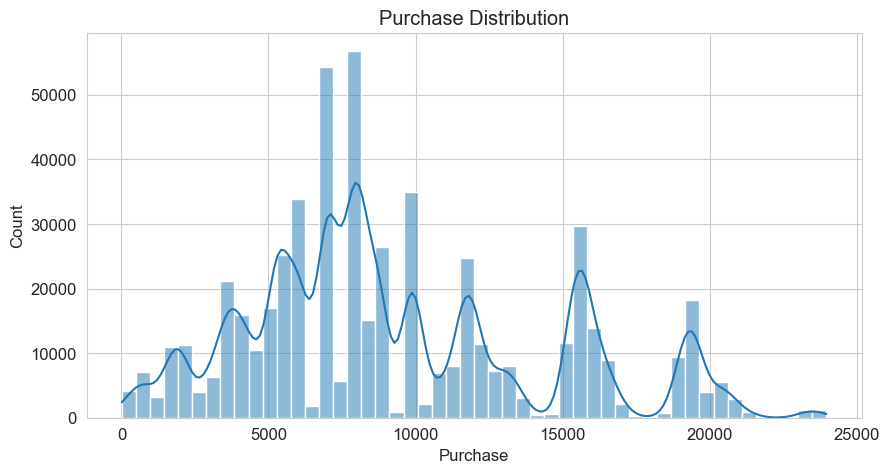

In [72]:
plt.figure(figsize=(10,5))
sns.histplot(df["Purchase"],bins=50,kde=True)
plt.title("Purchase Distribution")
plt.show()

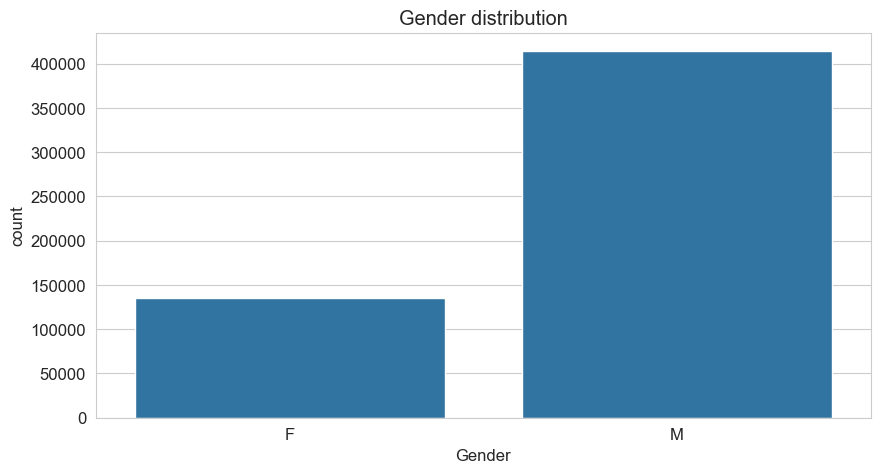

In [56]:
sns.countplot(data=df , x='Gender',)
plt.title("Gender distribution")
plt.show()


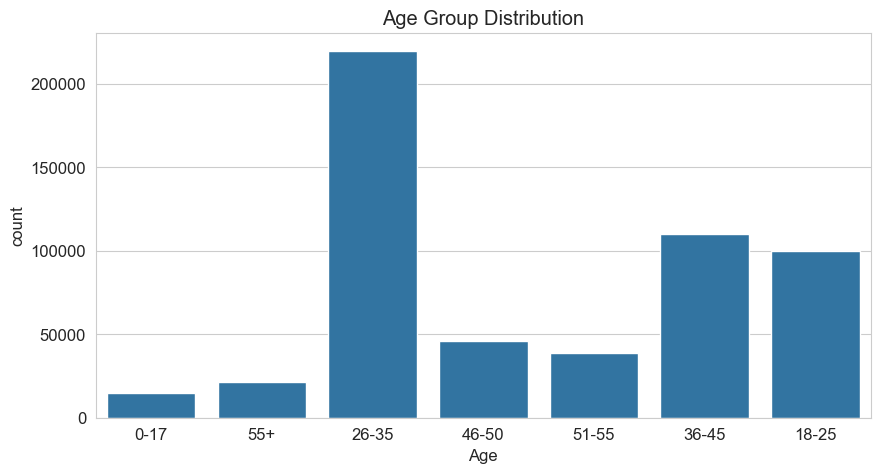

In [33]:
sns.countplot(data=df,x="Age")
plt.title("Age Group Distribution")
plt.show()


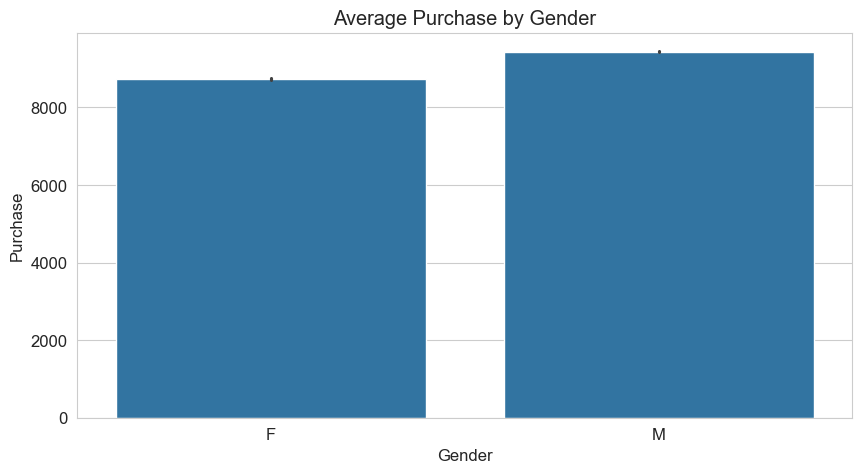

In [39]:
sns.barplot(data=df, x="Gender",y="Purchase")
plt.title("Average Purchase by Gender")
plt.show()

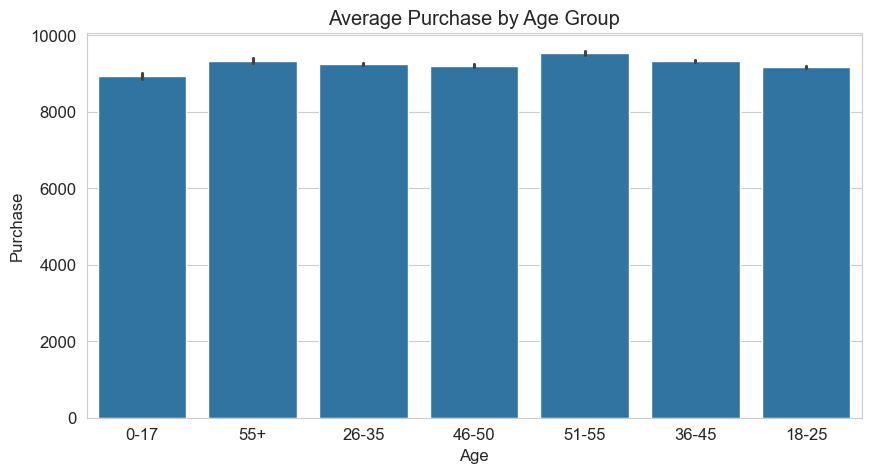

In [35]:
sns.barplot(data=df, x="Age", y="Purchase")
plt.title("Average Purchase by Age Group")
plt.show()

ValueError: 'red' is not a valid palette name

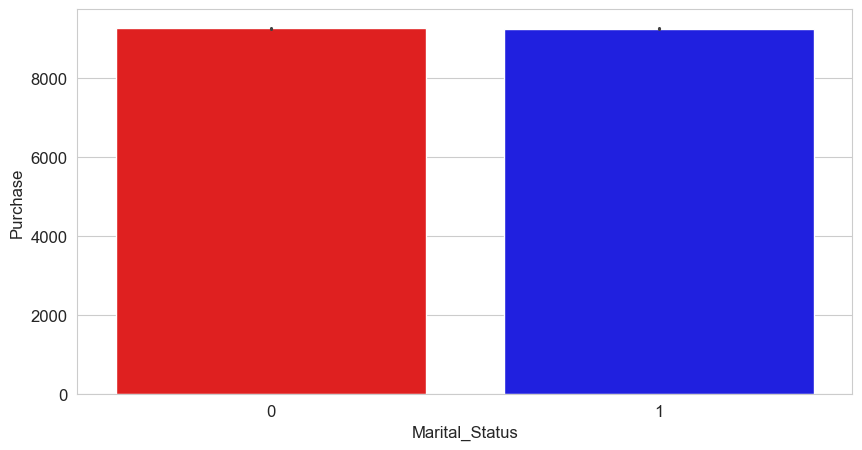

In [48]:
sns.barplot(data=df, x="Marital_Status", y="Purchase" , palette=[ "red","blue"] )
sns.barplot(data=df, y="Purchase", palette= "red")
plt.title("Purchase by Marital Status")
plt.show()

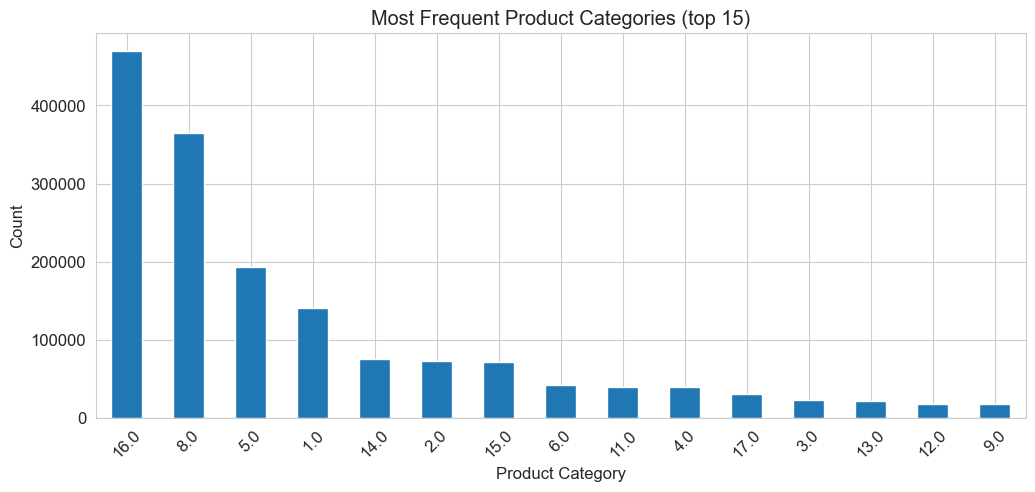

In [40]:
cat_counts = (
    df[["Product_Category_1","Product_Category_2","Product_Category_3"]]
    .melt(value_name="category")["category"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12,5))
cat_counts.plot(kind="bar")
plt.title("Most Frequent Product Categories (top 15)")
plt.xlabel("Product Category")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

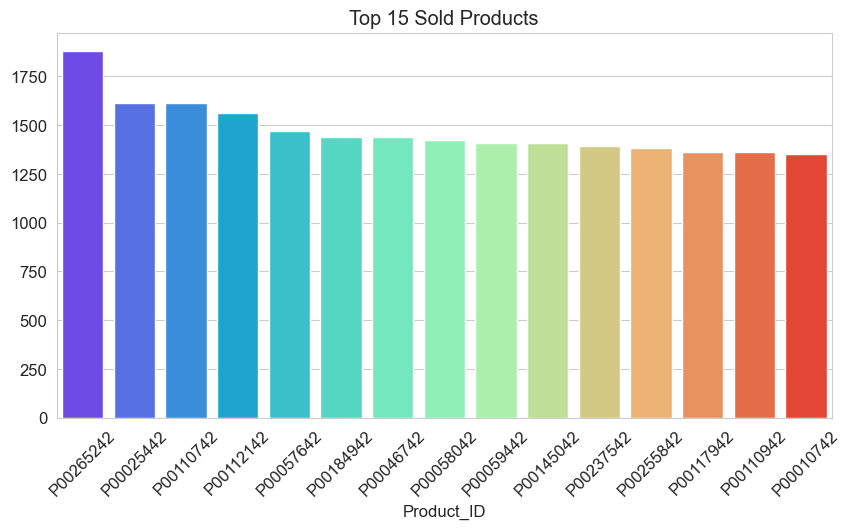

In [43]:
top_products = df["Product_ID"].value_counts().head(15)

sns.barplot(x=top_products.index, y=top_products.values, palette="rainbow" )
plt.xticks(rotation=45)
plt.title("Top 15 Sold Products")
plt.show()

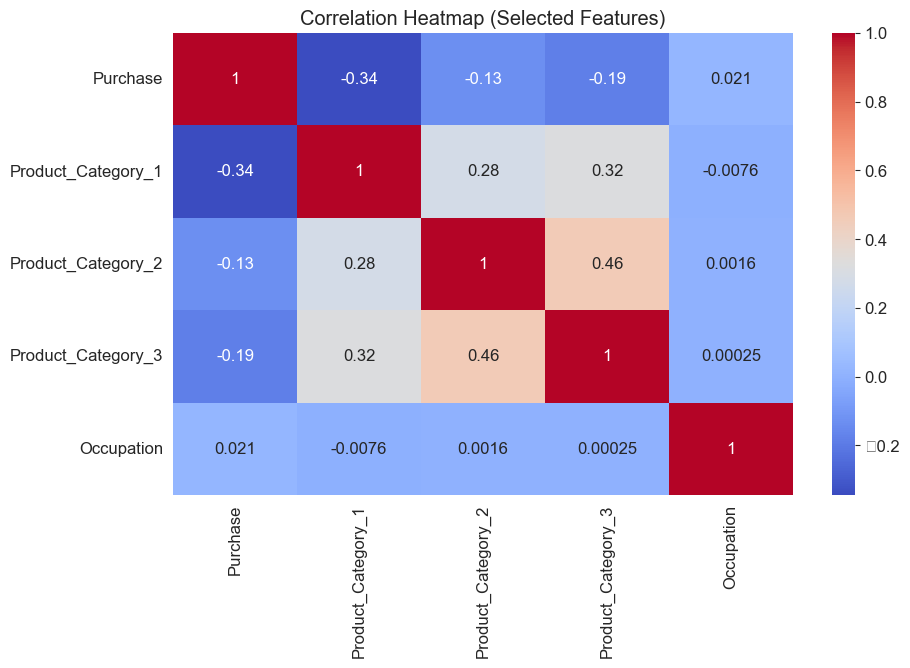

In [49]:
cols = ["Purchase", "Product_Category_1", "Product_Category_2", "Product_Category_3", "Occupation"]

plt.figure(figsize=(10,6))
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap (Selected Features)")
plt.show()

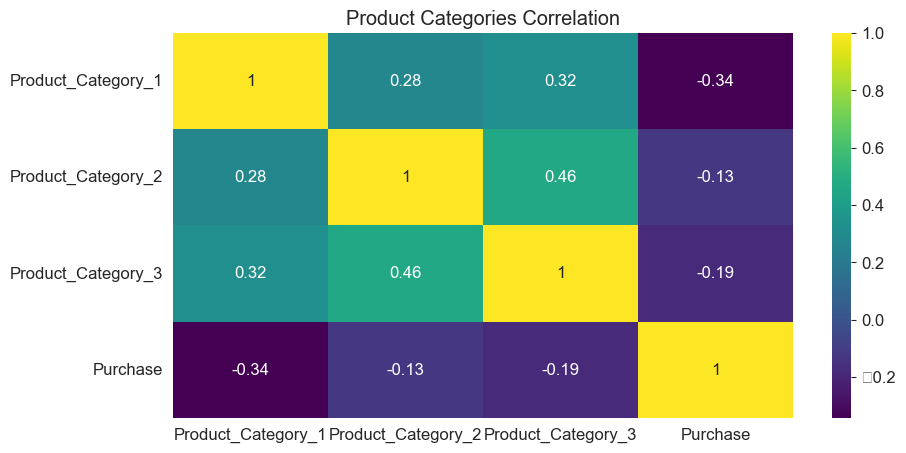

In [50]:
cat_corr = df[["Product_Category_1","Product_Category_2","Product_Category_3","Purchase"]].corr()

sns.heatmap(cat_corr, annot=True, cmap="viridis")
plt.title("Product Categories Correlation")
plt.show()

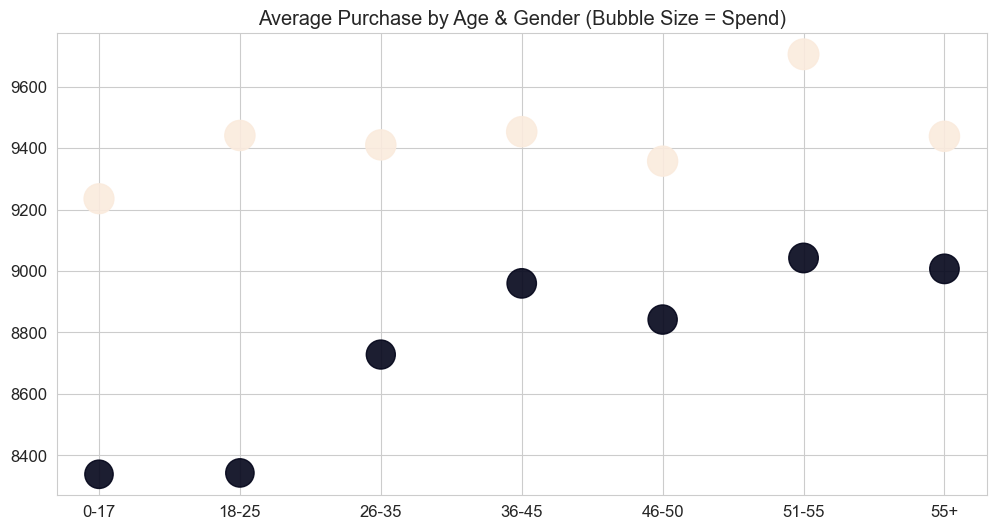

In [53]:
age_gender = df.groupby(["Age","Gender"])["Purchase"].mean().reset_index()

plt.figure(figsize=(12,6))
sizes = age_gender["Purchase"] / 20

plt.scatter(
    age_gender["Age"],
    age_gender["Purchase"],
    s=sizes,
    alpha=0.9,
    c=pd.factorize(age_gender["Gender"])[0]
)

plt.title("Average Purchase by Age & Gender (Bubble Size = Spend)")
plt.show()

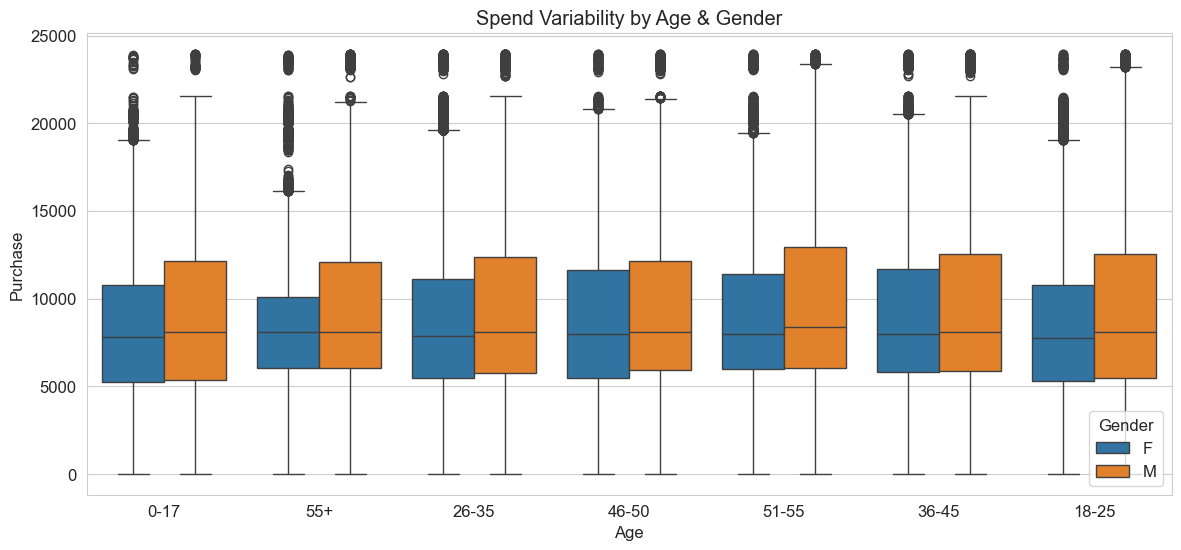

In [54]:
plt.figure(figsize=(14,6))
sns.boxplot(data=df, x="Age", y="Purchase", hue="Gender")
plt.title("Spend Variability by Age & Gender")
plt.show()